# MovieLens Feature Store: ER Model and Point-in-Time Training Data

## 0. Setup

In [6]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('pgserver') is None:
  subprocess.run(
    [sys.executable, '-m', 'pip', 'install', '-q', 'pgserver', 'sqlalchemy>=2.0,<2.1', 'psycopg2-binary', 'pandas'],
    check=True,
  )

In [8]:
import os
import urllib.request
import zipfile

import pandas as pd
from pgserver.postgres_server import get_server
from sqlalchemy import create_engine, text

pg = get_server('/tmp/pg_data')
engine = create_engine(pg.get_uri(), isolation_level='AUTOCOMMIT', connect_args={'options': '-c timezone=UTC'})
conn = engine.connect()

conn.exec_driver_sql('SELECT version()').scalar()

'PostgreSQL 16.2 on aarch64-apple-darwin23.5.0, compiled by Apple clang version 15.0.0 (clang-1500.0.40.1), 64-bit'

In [12]:
def run_sql(sql: str) -> None:
  conn.execute(text(sql))


def query(sql: str) -> pd.DataFrame:
  result = conn.execute(text(sql))

  return pd.DataFrame(result.fetchall(), columns=list(result.keys()))


def copy_csv(table: str, path: str, options: str = 'FORMAT csv, HEADER true') -> int:
  raw_conn = engine.raw_connection()
  cursor = raw_conn.cursor()
  with open(path, encoding='utf-8') as csv_file:
    cursor.copy_expert(f'COPY {table} FROM STDIN WITH ({options})', csv_file)
  loaded_rows = cursor.rowcount
  raw_conn.commit()
  raw_conn.close()

  return loaded_rows

In [16]:
DATA_DIR = 'data'
MOVIELENS_URL = 'https://files.grouplens.org/datasets/movielens/ml-latest-small.zip'
MOVIELENS_DIR = os.path.join(DATA_DIR, 'ml-latest-small')

if not os.path.exists(MOVIELENS_DIR):
  os.makedirs(DATA_DIR, exist_ok=True)
  archive_path = os.path.join(DATA_DIR, 'ml-latest-small.zip')
  urllib.request.urlretrieve(MOVIELENS_URL, archive_path)
  with zipfile.ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR)

sorted(os.listdir(MOVIELENS_DIR))

['README.txt', 'links.csv', 'movies.csv', 'ratings.csv', 'tags.csv']

## 1. ER diagram

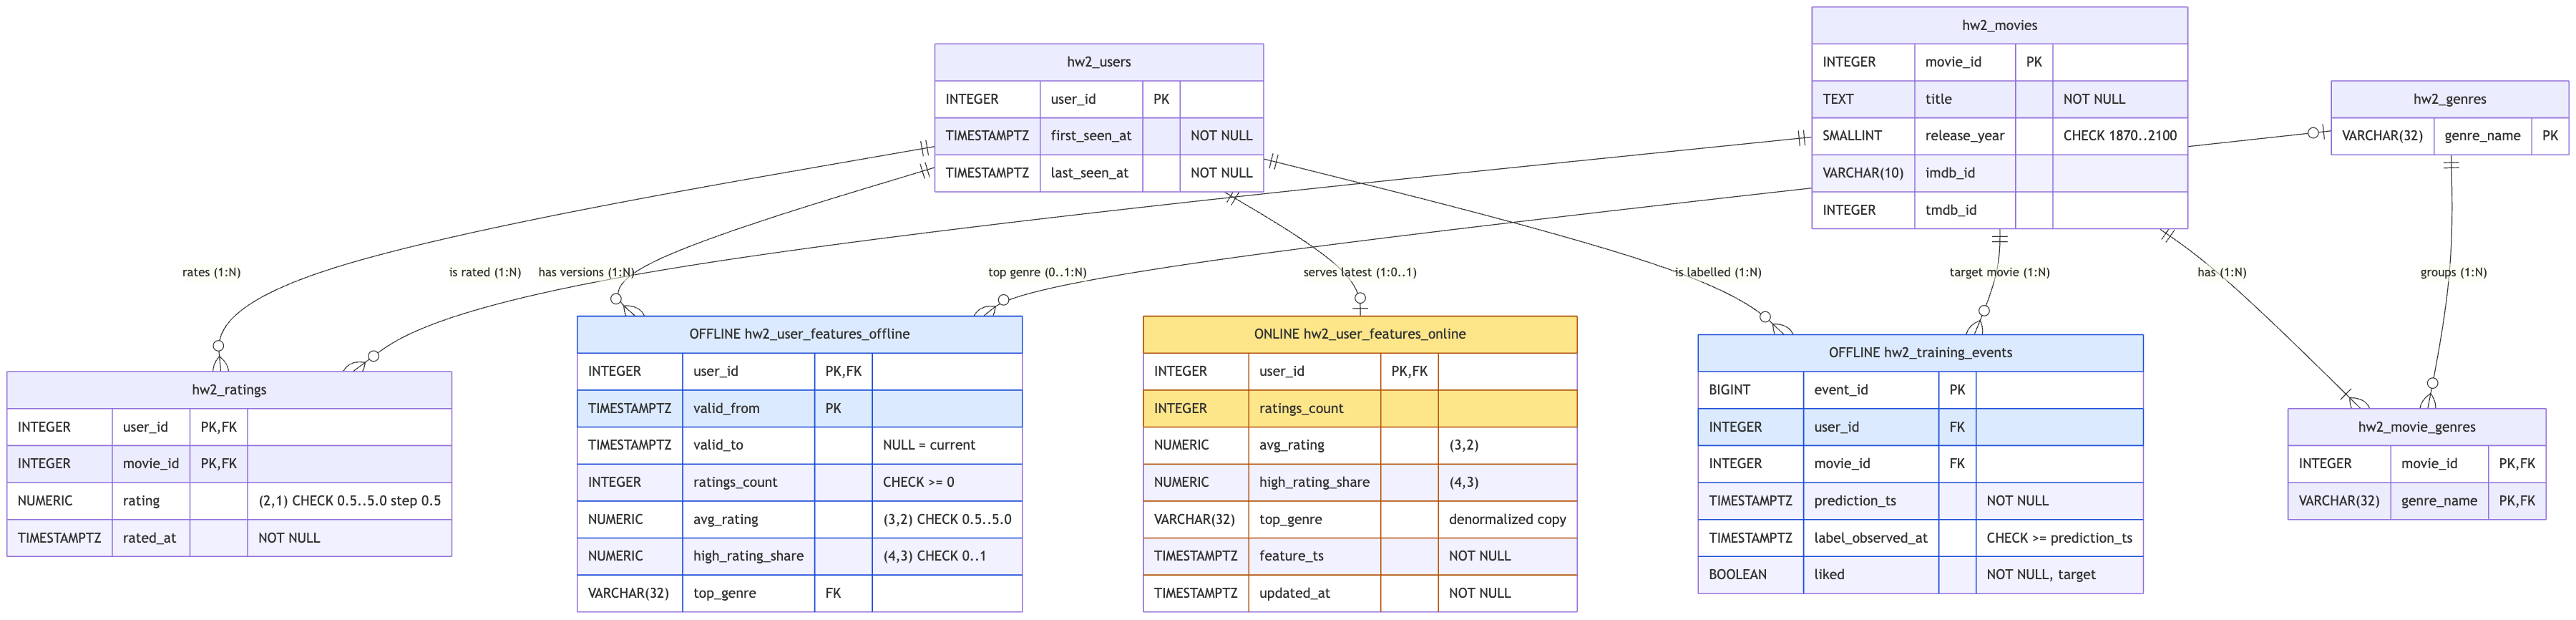

## 2. DDL

In [18]:
run_sql('''
SET TIME ZONE 'UTC';

DROP TABLE IF EXISTS
  hw2_user_features_online,
  hw2_training_events,
  hw2_user_features_offline,
  hw2_ratings,
  hw2_movie_genres,
  hw2_genres,
  hw2_movies,
  hw2_users,
  hw2_stg_movies,
  hw2_stg_links,
  hw2_stg_ratings
CASCADE;
''')

In [20]:
run_sql('''
CREATE TABLE hw2_users (
  user_id INTEGER PRIMARY KEY,
  first_seen_at TIMESTAMPTZ NOT NULL,
  last_seen_at TIMESTAMPTZ NOT NULL,
  CHECK (last_seen_at >= first_seen_at)
);

CREATE TABLE hw2_movies (
  movie_id INTEGER PRIMARY KEY,
  title TEXT NOT NULL,
  release_year SMALLINT CHECK (release_year BETWEEN 1870 AND 2100),
  imdb_id VARCHAR(10),
  tmdb_id INTEGER
);

CREATE TABLE hw2_genres (
  genre_name VARCHAR(32) PRIMARY KEY
);

CREATE TABLE hw2_movie_genres (
  movie_id INTEGER NOT NULL REFERENCES hw2_movies (movie_id),
  genre_name VARCHAR(32) NOT NULL REFERENCES hw2_genres (genre_name),
  PRIMARY KEY (movie_id, genre_name)
);

CREATE TABLE hw2_ratings (
  user_id INTEGER NOT NULL REFERENCES hw2_users (user_id),
  movie_id INTEGER NOT NULL REFERENCES hw2_movies (movie_id),
  rating NUMERIC(2, 1) NOT NULL CHECK (rating BETWEEN 0.5 AND 5.0 AND rating * 2 = TRUNC(rating * 2)),
  rated_at TIMESTAMPTZ NOT NULL,
  PRIMARY KEY (user_id, movie_id)
);

CREATE INDEX hw2_idx_ratings_user_time ON hw2_ratings (user_id, rated_at);
''')

In [45]:
run_sql('''
CREATE TABLE hw2_user_features_offline (
  user_id INTEGER NOT NULL REFERENCES hw2_users (user_id),
  valid_from TIMESTAMPTZ NOT NULL,
  valid_to TIMESTAMPTZ,
  ratings_count INTEGER NOT NULL CHECK (ratings_count >= 0),
  avg_rating NUMERIC(3, 2) CHECK (avg_rating IS NULL OR avg_rating BETWEEN 0.5 AND 5.0),
  high_rating_share NUMERIC(4, 3) CHECK (high_rating_share IS NULL OR high_rating_share BETWEEN 0 AND 1),
  top_genre VARCHAR(32) REFERENCES hw2_genres (genre_name),
  PRIMARY KEY (user_id, valid_from),
  CHECK (valid_to IS NULL OR valid_to > valid_from)
);

CREATE INDEX hw2_idx_user_features_asof ON hw2_user_features_offline (user_id, valid_from DESC);

CREATE TABLE hw2_training_events (
  event_id BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
  user_id INTEGER NOT NULL REFERENCES hw2_users (user_id),
  movie_id INTEGER NOT NULL REFERENCES hw2_movies (movie_id),
  prediction_ts TIMESTAMPTZ NOT NULL,
  label_observed_at TIMESTAMPTZ NOT NULL,
  liked BOOLEAN NOT NULL,
  CHECK (label_observed_at >= prediction_ts)
);

CREATE INDEX hw2_idx_training_events_user_ts ON hw2_training_events (user_id, prediction_ts);

CREATE TABLE hw2_user_features_online (
  user_id INTEGER PRIMARY KEY REFERENCES hw2_users (user_id),
  ratings_count INTEGER NOT NULL CHECK (ratings_count >= 0),
  avg_rating NUMERIC(3, 2) CHECK (avg_rating IS NULL OR avg_rating BETWEEN 0.5 AND 5.0),
  high_rating_share NUMERIC(4, 3) CHECK (high_rating_share IS NULL OR high_rating_share BETWEEN 0 AND 1),
  top_genre VARCHAR(32),
  feature_ts TIMESTAMPTZ NOT NULL,
  updated_at TIMESTAMPTZ NOT NULL DEFAULT CURRENT_TIMESTAMP
);
''')

query('''
SELECT table_name, COUNT(*) AS columns
FROM information_schema.columns
WHERE table_schema = 'public' AND table_name LIKE 'hw2\\_%'
GROUP BY table_name
ORDER BY table_name
''')

,table_name,columns
0,hw2_genres,1
1,hw2_movie_genres,2
2,hw2_movies,5
3,hw2_ratings,4
4,hw2_training_events,6
5,hw2_user_features_offline,7
6,hw2_user_features_online,7
7,hw2_users,3


## 3. Load MovieLens entities

In [49]:
run_sql('''
CREATE TABLE hw2_stg_movies (movie_id TEXT, title TEXT, genres TEXT);
CREATE TABLE hw2_stg_links (movie_id TEXT, imdb_id TEXT, tmdb_id TEXT);
CREATE TABLE hw2_stg_ratings (user_id TEXT, movie_id TEXT, rating TEXT, epoch_ts TEXT);
''')

{
  'movies': copy_csv('hw2_stg_movies', os.path.join(MOVIELENS_DIR, 'movies.csv')),
  'links': copy_csv('hw2_stg_links', os.path.join(MOVIELENS_DIR, 'links.csv')),
  'ratings': copy_csv('hw2_stg_ratings', os.path.join(MOVIELENS_DIR, 'ratings.csv')),
}

{'movies': 9742, 'links': 9742, 'ratings': 100836}

In [76]:
run_sql('''
INSERT INTO hw2_movies (movie_id, title, release_year, imdb_id, tmdb_id)
SELECT
  m.movie_id::INTEGER,
  TRIM(REGEXP_REPLACE(m.title, '\\s*\\((\\d{4})\\)\\s*$', '')),
  SUBSTRING(m.title FROM '\\((\\d{4})\\)\\s*$')::SMALLINT,
  'tt' || l.imdb_id,
  NULLIF(l.tmdb_id, '')::INTEGER
FROM hw2_stg_movies AS m
LEFT JOIN hw2_stg_links AS l ON l.movie_id = m.movie_id;

INSERT INTO hw2_genres (genre_name)
SELECT DISTINCT genre
FROM hw2_stg_movies, UNNEST(STRING_TO_ARRAY(genres, '|')) AS genre
WHERE genre <> '(no genres listed)';

INSERT INTO hw2_movie_genres (movie_id, genre_name)
SELECT DISTINCT movie_id::INTEGER, genre
FROM hw2_stg_movies, UNNEST(STRING_TO_ARRAY(genres, '|')) AS genre
WHERE genre <> '(no genres listed)';

INSERT INTO hw2_users (user_id, first_seen_at, last_seen_at)
SELECT user_id::INTEGER, TO_TIMESTAMP(MIN(epoch_ts::BIGINT)), TO_TIMESTAMP(MAX(epoch_ts::BIGINT))
FROM hw2_stg_ratings
GROUP BY user_id;

INSERT INTO hw2_ratings (user_id, movie_id, rating, rated_at)
SELECT user_id::INTEGER, movie_id::INTEGER, rating::NUMERIC(2, 1), TO_TIMESTAMP(epoch_ts::BIGINT)
FROM hw2_stg_ratings;

DROP TABLE hw2_stg_movies, hw2_stg_links, hw2_stg_ratings;
''')

query('''
SELECT 'hw2_users' AS table_name, COUNT(*) AS row_count FROM hw2_users
UNION ALL SELECT 'hw2_movies', COUNT(*) FROM hw2_movies
UNION ALL SELECT 'hw2_genres', COUNT(*) FROM hw2_genres
UNION ALL SELECT 'hw2_movie_genres', COUNT(*) FROM hw2_movie_genres
UNION ALL SELECT 'hw2_ratings', COUNT(*) FROM hw2_ratings
''')

,table_name,row_count
0,hw2_users,610
1,hw2_movies,9742
2,hw2_genres,19
3,hw2_movie_genres,22050
4,hw2_ratings,100836


In [77]:
query('''
SELECT m.movie_id, m.title, m.release_year, m.imdb_id, STRING_AGG(g.genre_name, ', ' ORDER BY g.genre_name) AS genres
FROM hw2_movies AS m
JOIN hw2_movie_genres AS g ON g.movie_id = m.movie_id
GROUP BY m.movie_id
ORDER BY m.movie_id
LIMIT 5
''')

,movie_id,title,release_year,imdb_id,genres
0,1,Toy Story,1995,tt0114709,"Adventure, Animation, Children, Comedy, Fantasy"
1,2,Jumanji,1995,tt0113497,"Adventure, Children, Fantasy"
2,3,Grumpier Old Men,1995,tt0113228,"Comedy, Romance"
3,4,Waiting to Exhale,1995,tt0114885,"Comedy, Drama, Romance"
4,5,Father of the Bride Part II,1995,tt0113041,Comedy


## 4. Normalization

`hw2_users`, `hw2_movies`, `hw2_genres`, `hw2_movie_genres` and `hw2_ratings` are in 3NF. Every value is atomic: the genre string `Action|Comedy` from `movies.csv` is split into the bridge table `hw2_movie_genres`, and the release year is moved out of the title into its own `release_year` column. In tables with a single-column key every attribute depends only on that key: `movie_id → title, release_year, imdb_id, tmdb_id` and `user_id → first_seen_at, last_seen_at`. `hw2_ratings` has a composite key, and `rating` and `rated_at` depend on the whole `(user_id, movie_id)` pair, not on a part of it. There are no transitive dependencies: `imdb_id` and `tmdb_id` describe the movie directly, so `links.csv` became columns of `hw2_movies` instead of a separate table. Genre names are stored once in `hw2_genres`.

`hw2_user_features_offline` is normalized as well: a feature version is identified by the key `(user_id, valid_from)`, and `top_genre` is a foreign key to the genre lookup.

`hw2_user_features_online` is denormalized on purpose. It holds one row per `user_id` with all current features and a copy of the genre name without a foreign key. The read pattern is a low-latency lookup by `user_id` during recommendation, so the query should be a single primary-key read with no `JOIN` and no search for the current version by interval. The risk is that the copy falls behind the offline source or drifts from it. That is why the online row is never edited by hand: it is only overwritten from the current offline version (`valid_to IS NULL`) through `INSERT ... ON CONFLICT DO UPDATE`, and `feature_ts` is stored to monitor freshness.

## 5. Historical features and training events

In [91]:
run_sql('''
INSERT INTO hw2_user_features_offline
  (user_id, valid_from, valid_to, ratings_count, avg_rating, high_rating_share, top_genre)
VALUES
  (106, TIMESTAMPTZ '2016-07-02 00:00:00+00', TIMESTAMPTZ '2016-07-04 00:00:00+00', 29, 4.38, 0.690, 'Adventure'),
  (106, TIMESTAMPTZ '2016-07-04 00:00:00+00', TIMESTAMPTZ '2017-01-21 00:00:00+00', 31, 4.40, 0.710, 'Adventure'),
  (106, TIMESTAMPTZ '2017-01-21 00:00:00+00', TIMESTAMPTZ '2017-03-15 00:00:00+00', 32, 4.42, 0.719, 'Adventure'),
  (106, TIMESTAMPTZ '2017-03-15 00:00:00+00', NULL, 33, 4.44, 0.727, 'Adventure'),
  (272, TIMESTAMPTZ '2018-07-23 00:00:00+00', TIMESTAMPTZ '2018-08-06 00:00:00+00', 14, 3.46, 0.500, 'Action'),
  (272, TIMESTAMPTZ '2018-08-06 00:00:00+00', TIMESTAMPTZ '2018-08-07 00:00:00+00', 22, 3.57, 0.500, 'Action'),
  (272, TIMESTAMPTZ '2018-08-07 00:00:00+00', TIMESTAMPTZ '2018-09-21 00:00:00+00', 29, 3.59, 0.517, 'Action'),
  (272, TIMESTAMPTZ '2018-09-21 00:00:00+00', NULL, 31, 3.63, 0.548, 'Action'),
  (557, TIMESTAMPTZ '2016-01-15 00:00:00+00', TIMESTAMPTZ '2016-01-16 00:00:00+00', 15, 4.03, 0.600, 'Action'),
  (557, TIMESTAMPTZ '2016-01-16 00:00:00+00', TIMESTAMPTZ '2016-01-17 00:00:00+00', 22, 3.77, 0.545, 'Action'),
  (557, TIMESTAMPTZ '2016-01-17 00:00:00+00', TIMESTAMPTZ '2016-01-20 00:00:00+00', 23, 3.76, 0.522, 'Action'),
  (557, TIMESTAMPTZ '2016-01-20 00:00:00+00', TIMESTAMPTZ '2016-01-23 00:00:00+00', 24, 3.79, 0.542, 'Action'),
  (557, TIMESTAMPTZ '2016-01-23 00:00:00+00', NULL, 27, 3.85, 0.593, 'Adventure');
''')

query('''
SELECT *
FROM hw2_user_features_offline
ORDER BY user_id, valid_from
''')

,user_id,valid_from,valid_to,ratings_count,avg_rating,high_rating_share,top_genre
0,106,2016-07-02 00:00:00+00:00,2016-07-04 00:00:00+00:00,29,4.38,0.690,Adventure
1,106,2016-07-04 00:00:00+00:00,2017-01-21 00:00:00+00:00,31,4.40,0.710,Adventure
2,106,2017-01-21 00:00:00+00:00,2017-03-15 00:00:00+00:00,32,4.42,0.719,Adventure
3,106,2017-03-15 00:00:00+00:00,NaT,33,4.44,0.727,Adventure
4,272,2018-07-23 00:00:00+00:00,2018-08-06 00:00:00+00:00,14,3.46,0.500,Action
5,272,2018-08-06 00:00:00+00:00,2018-08-07 00:00:00+00:00,22,3.57,0.500,Action
6,272,2018-08-07 00:00:00+00:00,2018-09-21 00:00:00+00:00,29,3.59,0.517,Action
7,272,2018-09-21 00:00:00+00:00,NaT,31,3.63,0.548,Action
8,557,2016-01-15 00:00:00+00:00,2016-01-16 00:00:00+00:00,15,4.03,0.600,Action
9,557,2016-01-16 00:00:00+00:00,2016-01-17 00:00:00+00:00,22,3.77,0.545,Action


In [95]:
query('''
WITH recomputed AS (
  SELECT
    f.user_id,
    f.valid_from,
    COUNT(*) AS ratings_count,
    ROUND(AVG(r.rating), 2) AS avg_rating,
    ROUND(AVG((r.rating >= 4)::INT), 3) AS high_rating_share
  FROM hw2_user_features_offline AS f
  JOIN hw2_ratings AS r
    ON r.user_id = f.user_id
    AND r.rated_at < f.valid_from
  GROUP BY f.user_id, f.valid_from
)
SELECT
  COUNT(*) AS versions_checked,
  COUNT(*) FILTER (
    WHERE f.ratings_count <> c.ratings_count
      OR f.avg_rating <> c.avg_rating
      OR f.high_rating_share <> c.high_rating_share
  ) AS mismatches
FROM hw2_user_features_offline AS f
JOIN recomputed AS c USING (user_id, valid_from)
''')

,versions_checked,mismatches
0,13,0


In [97]:
run_sql('''
INSERT INTO hw2_training_events
  (user_id, movie_id, prediction_ts, label_observed_at, liked)
VALUES
  (106, 7153, TIMESTAMPTZ '2016-07-01 00:00:00+00', TIMESTAMPTZ '2016-07-01 08:04:43+00', TRUE),
  (106, 99636, TIMESTAMPTZ '2016-07-03 00:00:00+00', TIMESTAMPTZ '2016-07-03 17:37:29+00', TRUE),
  (106, 47099, TIMESTAMPTZ '2017-01-20 00:00:00+00', TIMESTAMPTZ '2017-01-20 16:26:08+00', TRUE),
  (106, 318, TIMESTAMPTZ '2017-03-14 00:00:00+00', TIMESTAMPTZ '2017-03-14 13:34:32+00', TRUE),
  (272, 318, TIMESTAMPTZ '2018-07-22 00:00:00+00', TIMESTAMPTZ '2018-07-22 13:25:40+00', TRUE),
  (272, 177765, TIMESTAMPTZ '2018-08-05 00:00:00+00', TIMESTAMPTZ '2018-08-05 17:36:40+00', TRUE),
  (272, 3147, TIMESTAMPTZ '2018-08-06 00:00:00+00', TIMESTAMPTZ '2018-08-06 14:33:59+00', TRUE),
  (272, 148626, TIMESTAMPTZ '2018-09-20 00:00:00+00', TIMESTAMPTZ '2018-09-20 19:10:12+00', TRUE),
  (557, 318, TIMESTAMPTZ '2016-01-14 00:00:00+00', TIMESTAMPTZ '2016-01-14 18:47:48+00', TRUE),
  (557, 150, TIMESTAMPTZ '2016-01-15 00:00:00+00', TIMESTAMPTZ '2016-01-15 16:16:16+00', TRUE),
  (557, 134130, TIMESTAMPTZ '2016-01-16 00:00:00+00', TIMESTAMPTZ '2016-01-16 08:54:02+00', FALSE),
  (557, 1485, TIMESTAMPTZ '2016-01-19 00:00:00+00', TIMESTAMPTZ '2016-01-19 19:50:04+00', TRUE),
  (557, 1291, TIMESTAMPTZ '2016-01-22 00:00:00+00', TIMESTAMPTZ '2016-01-22 13:02:38+00', TRUE);
''')

query('''
SELECT e.*, r.rating
FROM hw2_training_events AS e
JOIN hw2_ratings AS r USING (user_id, movie_id)
ORDER BY e.event_id
''')

,event_id,user_id,movie_id,prediction_ts,label_observed_at,liked,rating
0,1,106,7153,2016-07-01 00:00:00+00:00,2016-07-01 08:04:43+00:00,True,5.0
1,2,106,99636,2016-07-03 00:00:00+00:00,2016-07-03 17:37:29+00:00,True,5.0
2,3,106,47099,2017-01-20 00:00:00+00:00,2017-01-20 16:26:08+00:00,True,5.0
3,4,106,318,2017-03-14 00:00:00+00:00,2017-03-14 13:34:32+00:00,True,5.0
4,5,272,318,2018-07-22 00:00:00+00:00,2018-07-22 13:25:40+00:00,True,4.0
5,6,272,177765,2018-08-05 00:00:00+00:00,2018-08-05 17:36:40+00:00,True,5.0
6,7,272,3147,2018-08-06 00:00:00+00:00,2018-08-06 14:33:59+00:00,True,4.5
7,8,272,148626,2018-09-20 00:00:00+00:00,2018-09-20 19:10:12+00:00,True,4.5
8,9,557,318,2016-01-14 00:00:00+00:00,2016-01-14 18:47:48+00:00,True,4.5
9,10,557,150,2016-01-15 00:00:00+00:00,2016-01-15 16:16:16+00:00,True,4.5


## 6. AS-OF queries

In [99]:
query('''
SELECT user_id, ratings_count, avg_rating, high_rating_share, top_genre, valid_from, valid_to
FROM hw2_user_features_offline
WHERE user_id = 557
  AND valid_from <= TIMESTAMPTZ '2016-01-16 12:00:00+00'
  AND (valid_to > TIMESTAMPTZ '2016-01-16 12:00:00+00' OR valid_to IS NULL)
''')

,user_id,ratings_count,avg_rating,high_rating_share,top_genre,valid_from,valid_to
0,557,22,3.77,0.545,Action,2016-01-16 00:00:00+00:00,2016-01-17 00:00:00+00:00


In [102]:
query('''
SELECT user_id, ratings_count, avg_rating, high_rating_share, top_genre, valid_from, valid_to
FROM hw2_user_features_offline
WHERE user_id = 557
  AND valid_from <= TIMESTAMPTZ '2016-01-20 00:00:00+00'
  AND (valid_to > TIMESTAMPTZ '2016-01-20 00:00:00+00' OR valid_to IS NULL)
''')

,user_id,ratings_count,avg_rating,high_rating_share,top_genre,valid_from,valid_to
0,557,24,3.79,0.542,Action,2016-01-20 00:00:00+00:00,2016-01-23 00:00:00+00:00


In [104]:
query('''
SELECT user_id, ratings_count, avg_rating, top_genre, valid_from, valid_to
FROM hw2_user_features_offline
WHERE user_id = 106
  AND valid_from <= TIMESTAMPTZ '2018-01-01 00:00:00+00'
  AND (valid_to > TIMESTAMPTZ '2018-01-01 00:00:00+00' OR valid_to IS NULL)
''')

,user_id,ratings_count,avg_rating,top_genre,valid_from,valid_to
0,106,33,4.44,Adventure,2017-03-15 00:00:00+00:00,None


In [138]:
query('''
SELECT
  e.event_id,
  e.user_id,
  e.movie_id,
  e.prediction_ts,
  e.liked,
  f.ratings_count,
  f.avg_rating,
  f.high_rating_share,
  f.top_genre,
  f.valid_from AS feature_valid_from
FROM hw2_training_events AS e
LEFT JOIN hw2_user_features_offline AS f
  ON f.user_id = e.user_id
  AND f.valid_from <= e.prediction_ts
  AND (f.valid_to > e.prediction_ts OR f.valid_to IS NULL)
ORDER BY e.event_id
''')

,event_id,user_id,movie_id,prediction_ts,liked,ratings_count,avg_rating,high_rating_share,top_genre,feature_valid_from
0,1,106,7153,2016-07-01 00:00:00+00:00,True,NaN,None,None,NaN,NaT
1,2,106,99636,2016-07-03 00:00:00+00:00,True,29.0,4.38,0.690,Adventure,2016-07-02 00:00:00+00:00
2,3,106,47099,2017-01-20 00:00:00+00:00,True,31.0,4.40,0.710,Adventure,2016-07-04 00:00:00+00:00
3,4,106,318,2017-03-14 00:00:00+00:00,True,32.0,4.42,0.719,Adventure,2017-01-21 00:00:00+00:00
4,5,272,318,2018-07-22 00:00:00+00:00,True,NaN,None,None,NaN,NaT
5,6,272,177765,2018-08-05 00:00:00+00:00,True,14.0,3.46,0.500,Action,2018-07-23 00:00:00+00:00
6,7,272,3147,2018-08-06 00:00:00+00:00,True,22.0,3.57,0.500,Action,2018-08-06 00:00:00+00:00
7,8,272,148626,2018-09-20 00:00:00+00:00,True,29.0,3.59,0.517,Action,2018-08-07 00:00:00+00:00
8,9,557,318,2016-01-14 00:00:00+00:00,True,NaN,None,None,NaN,NaT
9,10,557,150,2016-01-15 00:00:00+00:00,True,15.0,4.03,0.600,Action,2016-01-15 00:00:00+00:00


## 7. Interval and leakage checks

In [139]:
query('''
SELECT
  a.user_id,
  a.valid_from AS a_from,
  a.valid_to AS a_to,
  b.valid_from AS b_from,
  b.valid_to AS b_to
FROM hw2_user_features_offline AS a
JOIN hw2_user_features_offline AS b
  ON a.user_id = b.user_id
  AND a.valid_from < COALESCE(b.valid_to, 'infinity'::TIMESTAMPTZ)
  AND b.valid_from < COALESCE(a.valid_to, 'infinity'::TIMESTAMPTZ)
  AND a.valid_from < b.valid_from
''')

,user_id,a_from,a_to,b_from,b_to


In [140]:
query('''
SELECT
  a.user_id,
  a.valid_to AS previous_valid_to,
  b.valid_from AS next_valid_from
FROM hw2_user_features_offline AS a
JOIN hw2_user_features_offline AS b
  ON b.user_id = a.user_id
  AND b.valid_from = (
    SELECT MIN(valid_from)
    FROM hw2_user_features_offline
    WHERE user_id = a.user_id AND valid_from > a.valid_from
  )
WHERE a.valid_to IS DISTINCT FROM b.valid_from
''')

,user_id,previous_valid_to,next_valid_from


In [163]:
query('''
SELECT
  (SELECT COUNT(*) FROM hw2_training_events) AS training_events,
  (
    SELECT COUNT(*)
    FROM hw2_training_events AS e
    JOIN hw2_user_features_offline AS f ON f.user_id = e.user_id
  ) AS naive_join_rows,
  (
    SELECT COUNT(*)
    FROM hw2_training_events AS e
    JOIN hw2_user_features_offline AS f ON f.user_id = e.user_id
    WHERE f.valid_from > e.prediction_ts
  ) AS rows_with_future_features,
  (
    SELECT COUNT(*)
    FROM hw2_training_events AS e
    LEFT JOIN hw2_user_features_offline AS f
      ON f.user_id = e.user_id
      AND f.valid_from <= e.prediction_ts
      AND (f.valid_to > e.prediction_ts OR f.valid_to IS NULL)
  ) AS as_of_join_rows
''')

,training_events,naive_join_rows,rows_with_future_features,as_of_join_rows
0,13,57,35,13


## 8. Why the AS-OF condition looks like this

1. `valid_from <= prediction_ts` keeps only feature versions that already existed at prediction time. A version that appeared later is built from ratings the model had not seen yet.
2. `valid_to > prediction_ts OR valid_to IS NULL` drops versions that a newer one had already replaced at prediction time. `valid_to IS NULL` marks the current version with no upper bound, and a comparison with `NULL` returns `NULL`, so without the `OR` the current version would never appear in the result.
3. The interval `[valid_from, valid_to)` is half-open because the `valid_to` of one version equals the `valid_from` of the next. The boundary belongs only to the new version, so every moment, including exactly midnight, falls into exactly one version. With a closed interval two versions would match on the boundary.
4. Without a time filter, a plain `JOIN` on `user_id` returns 57 rows instead of 13: every event gets all versions of its user, and 35 of them start after `prediction_ts`. For example, the 2016-01-14 event of user 557 would receive `ratings_count = 27` and `top_genre = Adventure` as of 23 January, that is, a count and an average that include the ratings that are the labels of other training events. The model would learn from the future and validation metrics would be inflated.

The first event of each user (`event_id` 1, 5, 9) has no feature at all: this is a cold start, and the `LEFT JOIN` leaves them as `NULL` instead of picking a later version.

## 9. Online store refresh

In [164]:
run_sql('''
INSERT INTO hw2_user_features_online
  (user_id, ratings_count, avg_rating, high_rating_share, top_genre, feature_ts)
SELECT user_id, ratings_count, avg_rating, high_rating_share, top_genre, valid_from
FROM hw2_user_features_offline
WHERE valid_to IS NULL
ON CONFLICT (user_id) DO UPDATE SET
  ratings_count = EXCLUDED.ratings_count,
  avg_rating = EXCLUDED.avg_rating,
  high_rating_share = EXCLUDED.high_rating_share,
  top_genre = EXCLUDED.top_genre,
  feature_ts = EXCLUDED.feature_ts,
  updated_at = CURRENT_TIMESTAMP
WHERE EXCLUDED.feature_ts > hw2_user_features_online.feature_ts;
''')

query('''
SELECT user_id, ratings_count, avg_rating, high_rating_share, top_genre, feature_ts
FROM hw2_user_features_online
ORDER BY user_id
''')

,user_id,ratings_count,avg_rating,high_rating_share,top_genre,feature_ts
0,106,33,4.44,0.727,Adventure,2017-03-15 00:00:00+00:00
1,272,31,3.63,0.548,Action,2018-09-21 00:00:00+00:00
2,557,27,3.85,0.593,Adventure,2016-01-23 00:00:00+00:00


## 10. Reflection

**Hardest part.** The hardest part was deciding what the prediction moment is in MovieLens. A rating is both the event and the label. If `prediction_ts` is exactly the rating time and the feature version comes from the same second, the rating leaks into its own features. So feature versions start at midnight after the day of activity, and the prediction is made at the start of the rating day. Cardinalities and normalization were easier: MovieLens naturally has two N:M relationships (`users ↔ movies` through `hw2_ratings` and `movies ↔ genres` through `hw2_movie_genres`).

**Trade-offs.** The raw entities are normalized to 3NF because they are written rarely and read in many combinations, and every fact should live in one place. Offline features keep the full history keyed by `(user_id, valid_from)`: it costs more space, but gives reproducible training sets for any date. The online table is denormalized: one row per user and a copy of the genre name with no `JOIN`. It is read on every recommendation request and updated only in batches from the offline layer.

**Fast online lookup for millions of users.** I would keep the same denormalized row keyed by `user_id`, but materialize it ahead of time and serve it from a key-value cache (Redis) in front of PostgreSQL. The table can be sharded by a hash of `user_id` and reads spread over replicas. To control freshness, `feature_ts` is compared with a threshold: if a row is stale, the service falls back to default features or raises an alert.

**Schema evolution risks over six months.** Renaming or dropping a column breaks old training code, so changes should be additive: a new column, a period of dual writes, then removal. A change in semantics (for example `high_rating_share` with a 4.5 threshold instead of 4) must not silently overwrite the old feature: it needs a new name or a feature version. A type change (`NUMERIC(3,2)` → `NUMERIC(4,3)`) requires a backfill of the history. Old models must read the feature version they were trained on, so the schema version should be stored next to the model artifact.